# 38 · CIFAR-100 hierarchy and gallery protocol

Each 40-image gallery has five superclasses, four fine categories per superclass, and two images per fine category. The same ranked score matrices support two different questions. [Protocol and reproduction](../THEORY_STAGE12.md)

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
R = ROOT/'results'/'stage12'
import json
from observables.stage11 import average_precision
from observables.stage12 import ARCHIVE_MD5, tasks
members = pd.read_csv(R/'membership.csv')
manifest = json.loads((R/'manifest.json').read_text())
assert manifest['archive_md5'] == ARCHIVE_MD5
assert len(members) == members.source.nunique() == 480
assert members.gallery.nunique() == 12
assert members.groupby(['gallery','coarse']).size().eq(8).all()
assert members.groupby(['gallery','fine']).size().eq(2).all()
assert members.groupby('coarse').gallery.nunique().eq(3).all()
assert members.fine.nunique() == 100
display(pd.Series(manifest).to_frame('Setting'))


,Setting
dataset,CIFAR-100 official test
archive_md5,eb9058c3a382ffc7106e4002c42a8d85
test_sha256,4b67687d9933c4db8f0831104447f15b93774f4f464bd0...
seed,12427
galleries,12
superclasses_per_gallery,5
fine_classes_per_superclass,4
images_per_fine_class,2
color,RGB
conditions,"[clean, shift, gain, noise, blur, rotation, cr..."


## Candidate masks

Fine retrieval keeps the same superclass and finds the single same-fine-category match. Coarse retrieval drops the same-fine-category match and finds any of the six other images in the same superclass. Both remove the source. The random AP column is the expected AP for an uninformative ordering.

In [3]:
g = members.query('gallery == 0').sort_values(['coarse','fine','source']).reset_index(drop=True)
summary = []
for name, mask, truth in tasks(np.arange(40), 0, g.fine.to_numpy(), g.coarse.to_numpy()):
    n, p = int(mask.sum()), int(truth.sum())
    summary.append((name, n, p, 100*p/n, 100*average_precision(np.zeros(n),truth)))
display(pd.DataFrame(summary, columns=['task','candidates','positives','chance top-1 (%)',
                                       'expected random AP (%)']).round(2))


,task,candidates,positives,chance top-1 (%),expected random AP (%)
0,fine,7,1,14.29,37.04
1,coarse,38,6,15.79,23.14


## One gallery

Each row is a superclass. Adjacent image pairs share a fine label. The tiles are the native 32 × 32 RGB test images.

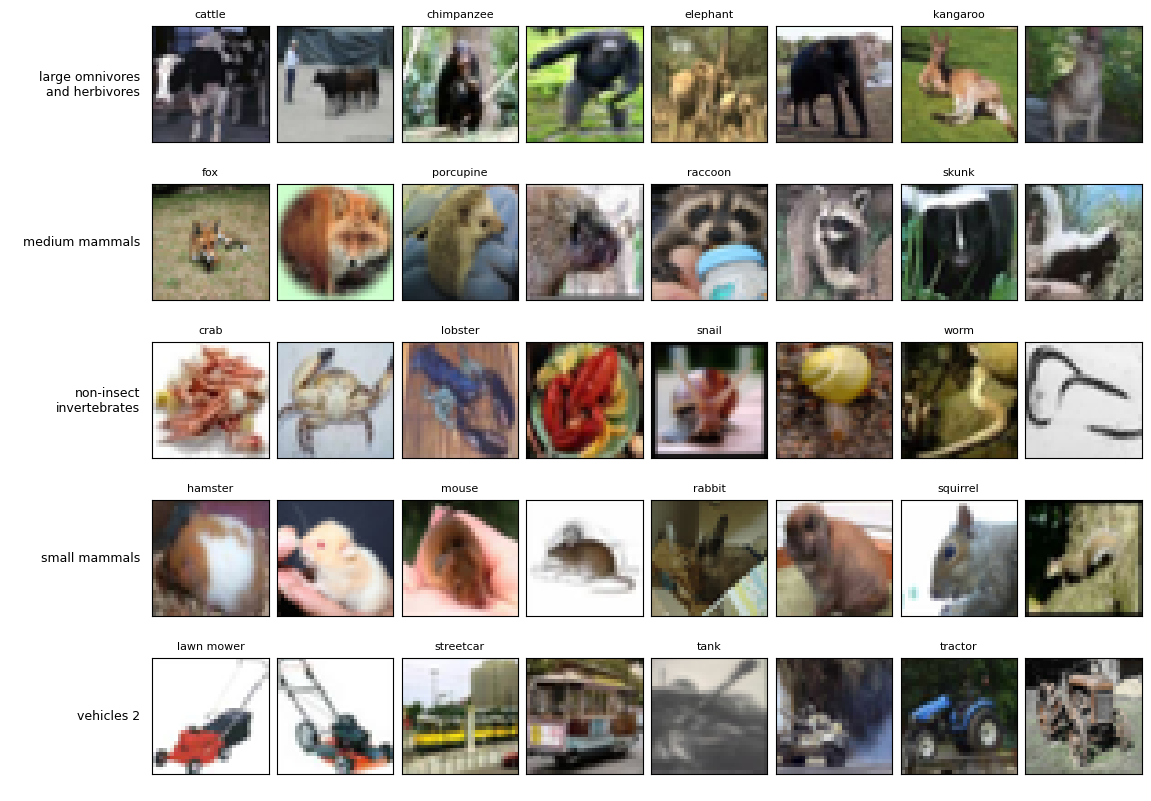

In [5]:
from textwrap import fill
with np.load(R/'gallery_preview.npz', allow_pickle=False) as preview:
    images = dict(zip(preview['source'], preview['images']))
assert set(g.source) == set(images)
fig, axes = plt.subplots(5, 9, figsize=(11.4, 7.9), layout='constrained',
                         gridspec_kw={'width_ratios':[1.15]+[1]*8})
for axes_row, (_, rows) in zip(axes, g.groupby('coarse')):
    axes_row[0].set_axis_off()
    label = fill(rows.coarse_name.iloc[0].replace('_',' '), 15)
    axes_row[0].text(.97, .5, label, fontsize=9, ha='right', va='center',
                     transform=axes_row[0].transAxes)
    for col, (ax, sample) in enumerate(zip(axes_row[1:], rows.itertuples())):
        ax.imshow(images[sample.source])
        ax.set(xticks=[], yticks=[])
        if col % 2 == 0:
            ax.set_title(sample.fine_name.replace('_',' '), fontsize=8)
fig.savefig(R/'38_hierarchical_gallery.png', dpi=150)
plt.show()
